# How Learning Rate Shapes the Journey of a Neural Network

*By Van Robert T. Edio | 4th-Year Data Science Student (DS4A), USTP*  
*Code Repository: [github.com/Vancey041/ds-portfolio](https://github.com/Vancey041/ds-portfolio)*

---

## 1. Introduction & Experimental Question

When training a neural network, few settings matter more than the **learning rate** ($\eta$). Imagine walking to the bottom of a foggy valley while blindfolded: at each step, you feel the downward slope (the **gradient**, $\nabla_{\theta} \mathcal{L}$) and take a stride of size $\eta$:

$$\theta_{t+1} = \theta_t - \eta \nabla_{\theta} \mathcal{L}(\theta_t)$$

If your stride is **too tiny**, you take baby steps and run out of time halfway down the hill; if it is **too huge**, you leap clear across the valley floor and bounce wildly between opposite walls without ever settling. Even with adaptive optimizers like **Adam**, the base learning rate sets the overall speed limit for weight updates.

Using our PyTorch Lightning pipeline (`hyperparameters_lightning.ipynb`) on **Fashion-MNIST**, I locked the model, data, and training rules while varying **only** the learning rate across four values ($10^{-4}$, $10^{-3}$, $5 \times 10^{-3}$, and $10^{-2}$) to answer one question:

> **What happens to a neural network's learning journey when the learning rate is too low, just right, or too high—with everything else held constant?**

### Environment Setup

Before training, I import our core experiment tools: **PyTorch** and **Torchvision** for neural network layers and dataset loading, **PyTorch Lightning** to structure the training loop cleanly, **Pandas** and **Matplotlib** for log parsing and learning curves, and **`dataclasses.replace`** so each run clones our base configuration and modifies *only* the learning rate. I also configure OS-safe DataLoader workers and suppress routine system warnings to keep output logs readable.

In [1]:
import os
import sys
import time
import warnings
from dataclasses import dataclass, replace, asdict
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from lightning.pytorch.loggers import CSVLogger

warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*save_hyperparameters.*")

DATA_DIR = Path("./data")
LOG_DIR = Path("./lightning_logs")
NUM_WORKERS = 0 if (os.name == "nt" or sys.platform == "darwin") else min(4, os.cpu_count() or 1)
print(f"PyTorch: {torch.__version__} | Lightning: {L.__version__} | Workers: {NUM_WORKERS}")

PyTorch: 2.14.0+cpu | Lightning: 2.6.6 | Workers: 0


## 2. Data, Model Architecture, and Fixed Baseline

To run a fair controlled experiment, we change **only one ingredient** at a time. Using the starter setup (`hyperparameters_lightning.ipynb`), I locked every experimental parameter inside `HParams`:

* **Dataset (`FashionMNISTDataModule`):** **Fashion-MNIST** contains $70{,}000$ grayscale clothing images ($28 \times 28$ pixels across 10 classes), normalized with mean `0.2860` and standard deviation `0.3530` (`augment=False` to avoid extra randomness). It is split into **54,000 training images** (for weight updates), **6,000 validation images** (for epoch-by-epoch comparison), and **10,000 held-out test images** (left completely untouched so we never tune on test accuracy).
* **Model (`SmallCNN`):** A compact Convolutional Neural Network with **206,922 trainable parameters**. Two convolutional blocks (`16` $\rightarrow$ `32` filters) extract visual features like edges and shoe soles, feeding a classifier head (`Dropout(0.25)` $\rightarrow$ `Linear(1568, 128)` $\rightarrow$ `Linear(128, 10)`).
* **Training Rules (`LitClassifier`):** All runs use the **Adam** optimizer, mini-batches of **64**, and random seed **42**. I set early-stopping `patience=12` so every learning rate runs the full **12 epochs** for a complete side-by-side trajectory.

**Table 1:** *Fixed experimental configuration locked across all four learning-rate runs.*

| Experiment Ingredient | Locked Setting |
| :--- | :--- |
| **Dataset & Splits** | Fashion-MNIST (`54,000` train / `6,000` val / `10,000` held-out test) |
| **Image Preprocessing** | Tensor + Normalize `(0.2860,), (0.3530,)`, `augment=False` |
| **Model (`SmallCNN`)** | 2 Conv blocks (`16` $\rightarrow$ `32` filters) + `128` hidden units, `ReLU`, `dropout=0.25` |
| **Model Size** | `206,922` trainable parameters |
| **Optimizer** | `Adam` (`weight_decay=0.0`, no learning rate scheduler) |
| **Batch Size & Length** | `batch_size=64`, `max_epochs=12` (`patience=12`) |
| **Random Seed** | `42` (`L.seed_everything(42, workers=True)`) |
| **Varied Hyperparameter** | Learning rate `lr` $\in \{10^{-4},\ 10^{-3},\ 5\times 10^{-3},\ 10^{-2}\}$ |

In [2]:
@dataclass
class HParams:
    # Data
    batch_size: int = 64
    val_fraction: float = 0.1
    augment: bool = False
    train_subset: int | None = None
    # Model
    conv1_channels: int = 16
    conv2_channels: int = 32
    hidden_dim: int = 128
    activation: str = "relu"
    dropout: float = 0.25
    use_batchnorm: bool = False
    # Optimization
    optimizer: str = "adam"
    lr: float = 1e-3
    momentum: float = 0.9
    weight_decay: float = 0.0
    scheduler: str = "none"
    step_size: int = 5
    gamma: float = 0.5
    # Training loop
    max_epochs: int = 12
    patience: int = 12
    seed: int = 42


class FashionMNISTDataModule(L.LightningDataModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.mean, self.std = (0.2860,), (0.3530,)

    def prepare_data(self):
        datasets.FashionMNIST(DATA_DIR, train=True, download=True)
        datasets.FashionMNIST(DATA_DIR, train=False, download=True)

    def setup(self, stage=None):
        eval_tf = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(self.mean, self.std),
        ])
        if self.hp.augment:
            train_tf = transforms.Compose([
                transforms.RandomHorizontalFlip(),
                transforms.RandomAffine(degrees=10, translate=(0.08, 0.08)),
                transforms.ToTensor(),
                transforms.Normalize(self.mean, self.std),
            ])
        else:
            train_tf = eval_tf

        full_train = datasets.FashionMNIST(DATA_DIR, train=True, transform=train_tf)
        full_val = datasets.FashionMNIST(DATA_DIR, train=True, transform=eval_tf)

        n_val = int(len(full_train) * self.hp.val_fraction)
        n_train = len(full_train) - n_val
        gen = torch.Generator().manual_seed(self.hp.seed)
        train_idx, val_idx = random_split(range(len(full_train)), [n_train, n_val], generator=gen)

        self.train_set = Subset(full_train, train_idx.indices)
        self.val_set = Subset(full_val, val_idx.indices)
        if self.hp.train_subset is not None:
            self.train_set = Subset(self.train_set, range(min(self.hp.train_subset, len(self.train_set))))
        self.test_set = datasets.FashionMNIST(DATA_DIR, train=False, transform=eval_tf)

    def _loader(self, dataset, shuffle: bool):
        return DataLoader(
            dataset,
            batch_size=self.hp.batch_size,
            shuffle=shuffle,
            num_workers=NUM_WORKERS,
            pin_memory=torch.cuda.is_available(),
            persistent_workers=NUM_WORKERS > 0,
        )

    def train_dataloader(self):
        return self._loader(self.train_set, shuffle=True)

    def val_dataloader(self):
        return self._loader(self.val_set, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_set, shuffle=False)


ACTIVATIONS = {
    "relu": nn.ReLU,
    "gelu": nn.GELU,
    "silu": nn.SiLU,
    "tanh": nn.Tanh,
}


class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        act_cls = ACTIVATIONS[hp.activation]

        def conv_block(in_c, out_c):
            layers = [nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, bias=not hp.use_batchnorm)]
            if hp.use_batchnorm:
                layers.append(nn.BatchNorm2d(out_c))
            layers.extend([act_cls(), nn.MaxPool2d(2)])
            return nn.Sequential(*layers)

        self.features = nn.Sequential(
            conv_block(1, hp.conv1_channels),
            conv_block(hp.conv1_channels, hp.conv2_channels),
        )
        flat_dim = hp.conv2_channels * 7 * 7
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(hp.dropout),
            nn.Linear(flat_dim, hp.hidden_dim),
            act_cls(),
            nn.Linear(hp.hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class LitClassifier(L.LightningModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.save_hyperparameters(asdict(hp))
        self.model = SmallCNN(hp)

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch, stage: str):
        x, y = batch
        logits = self(x)
        loss = F.cross_entropy(logits, y)
        acc = (logits.argmax(dim=-1) == y).float().mean()
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True, prog_bar=(stage == "val"))
        self.log(f"{stage}_acc", acc, on_step=False, on_epoch=True, prog_bar=(stage == "val"))
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._shared_step(batch, "test")

    def configure_optimizers(self):
        hp = self.hp
        if hp.optimizer == "sgd":
            opt = torch.optim.SGD(self.parameters(), lr=hp.lr, momentum=hp.momentum, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adam":
            opt = torch.optim.Adam(self.parameters(), lr=hp.lr, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adamw":
            opt = torch.optim.AdamW(self.parameters(), lr=hp.lr, weight_decay=hp.weight_decay)
        else:
            raise ValueError(f"Unknown optimizer: {hp.optimizer}")

        if hp.scheduler == "none":
            return opt
        if hp.scheduler == "step":
            sched = torch.optim.lr_scheduler.StepLR(opt, step_size=hp.step_size, gamma=hp.gamma)
        elif hp.scheduler == "cosine":
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=hp.max_epochs)
        else:
            raise ValueError(f"Unknown scheduler: {hp.scheduler}")
        return {"optimizer": opt, "lr_scheduler": {"scheduler": sched, "interval": "epoch"}}


def load_history(log_dir: str | Path) -> pd.DataFrame:
    df = pd.read_csv(Path(log_dir) / "metrics.csv")
    return df.groupby("epoch", as_index=False).first()


def fit(hp: HParams, run_name: str, verbose: bool = False, checkpoint: bool = False):
    L.seed_everything(hp.seed, workers=True)
    dm = FashionMNISTDataModule(hp)
    model = LitClassifier(hp)
    logger = CSVLogger(save_dir=LOG_DIR, name=run_name)
    callbacks = [EarlyStopping(monitor="val_loss", patience=hp.patience, mode="min")]
    if checkpoint:
        callbacks.append(ModelCheckpoint(monitor="val_loss", mode="min", save_top_k=1, filename="best"))

    trainer = L.Trainer(
        max_epochs=hp.max_epochs,
        accelerator="auto",
        devices=1,
        logger=logger,
        callbacks=callbacks,
        enable_progress_bar=verbose,
        enable_model_summary=verbose,
    )
    trainer.fit(model, datamodule=dm)
    history = load_history(logger.log_dir)
    return trainer, model, dm, history


base_hp = HParams(max_epochs=12, patience=12, seed=42)
print(f"Baseline SmallCNN trainable parameters: {count_parameters(SmallCNN(base_hp)):,}")

Baseline SmallCNN trainable parameters: 206,922


## Step 3: Running Each Learning Rate Separately and Inspecting the Results

Instead of running all four tests inside a single loop where everything blurs together, I gave each learning rate its own dedicated cell. Using `dataclasses.replace(base_hp, lr=...)`, I cloned our locked baseline recipe and changed **only** the learning rate for each run, while wrapping each training session with `time.perf_counter()` to see how many seconds it took to finish.

To keep our comparison completely fair, we judge every single run using **only the validation set** (`val_loss` and `val_acc`)—our 6,000 "practice quiz" images—leaving the 10,000 test images completely untouched. Here is what happened when we watched each learning rate train on its own.

### Run 1: The Tiny Stride (`lr = 1e-4` / `0.0001`)

In [3]:
t0 = time.perf_counter()
_, _, _, hist_1e4 = fit(replace(base_hp, lr=1e-4), run_name="lr_1e-4", verbose=True)
sec_1e4 = time.perf_counter() - t0
print(f"lr=1e-4 | Best Val Acc: {hist_1e4['val_acc'].max():.4f} | Final Val Loss: {hist_1e4['val_loss'].iloc[-1]:.4f} | Time: {sec_1e4:.1f}s")
display(hist_1e4[["epoch", "train_loss", "val_loss", "train_acc", "val_acc"]])

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ SmallCNN │  206 K │ train │     0 │
└───┴───────┴──────────┴────────┴───────┴───────┘

Trainable params: 206 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 206 K                                                                                                
Total estimated model params size (MB): 0.828                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

D:\BOB\anaconda3\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is 
deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_epochs=12` reached.


lr=1e-4 | Best Val Acc: 0.8988 | Final Val Loss: 0.2912 | Time: 309.3s


,epoch,train_loss,val_loss,train_acc,val_acc
0,0,0.745026,0.494956,0.748333,0.824500
1,1,0.474611,0.437463,0.828852,0.842833
2,2,0.422460,0.398202,0.847426,0.860500
3,3,0.394843,0.371762,0.857037,0.871333
4,4,0.373154,0.356517,0.865963,0.873500
5,5,0.354629,0.343706,0.871685,0.881333
6,6,0.341505,0.331828,0.876167,0.885000
7,7,0.331094,0.322481,0.880648,0.883333
8,8,0.321963,0.317517,0.883704,0.883333
9,9,0.310036,0.302614,0.889537,0.894167


**Analysis of `lr = 1e-4` (309.3s | Best Val Acc: 89.88% | Final Val Loss: 0.2912):**

* **Smooth Climb, Too Slow:** Validation loss drops steadily every single epoch (`0.4950` $\rightarrow$ `0.2912`) without a single bounce, climbing from `82.45%` to `89.88%` validation accuracy. The descent is completely stable, but steps of $0.0001$ are too small to reach the bottom before our 12-epoch timer runs out.
* **Why `val_acc` (`89.88%`) > `train_acc` (`89.35%`):** `Dropout(0.25)` disables 25% of neurons during training, whereas 100% of neurons stay active during validation.

### Run 2: Standard Adam Baseline (`lr = 1e-3`)

In [4]:
t0 = time.perf_counter()
_, _, _, hist_1e3 = fit(replace(base_hp, lr=1e-3), run_name="lr_1e-3", verbose=True)
sec_1e3 = time.perf_counter() - t0
print(f"lr=1e-3 | Best Val Acc: {hist_1e3['val_acc'].max():.4f} | Final Val Loss: {hist_1e3['val_loss'].iloc[-1]:.4f} | Time: {sec_1e3:.1f}s")
display(hist_1e3[["epoch", "train_loss", "val_loss", "train_acc", "val_acc"]])

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ SmallCNN │  206 K │ train │     0 │
└───┴───────┴──────────┴────────┴───────┴───────┘

Trainable params: 206 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 206 K                                                                                                
Total estimated model params size (MB): 0.828                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

D:\BOB\anaconda3\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is 
deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_epochs=12` reached.


lr=1e-3 | Best Val Acc: 0.9233 | Final Val Loss: 0.2164 | Time: 307.3s


,epoch,train_loss,val_loss,train_acc,val_acc
0,0,0.484011,0.374921,0.824796,0.863500
1,1,0.330965,0.304390,0.879667,0.884667
2,2,0.285190,0.285579,0.895222,0.893167
3,3,0.257441,0.243917,0.905259,0.908167
4,4,0.233659,0.238961,0.913130,0.909833
5,5,0.214933,0.227650,0.919963,0.915000
6,6,0.198179,0.225351,0.925148,0.918000
7,7,0.186704,0.241693,0.929018,0.911333
8,8,0.173387,0.224312,0.935204,0.916833
9,9,0.163324,0.206984,0.938444,0.923333


**Analysis of `lr = 1e-3` (307.3s | Best Val Acc: 92.33% | Final Val Loss: 0.2164):**

* **Fast, Clean Convergence:** Stepping up $10\times$ to Adam's default (`0.001`) hits `86.35%` validation accuracy in Epoch 0, crosses `90%` by Epoch 3, and peaks at **`92.33%`** (`0.2070` val loss) by Epoch 9—beating `1e-4` by **+2.45 percentage points**. Validation loss drops rapidly early on (`0.375` $\rightarrow$ `0.244`) before leveling off around `0.21–0.23`, showing the model reached the bottom of the valley well within 12 epochs.
* **Mild Late Overfitting:** After Epoch 6, `train_loss` keeps falling (`0.198` $\rightarrow$ `0.143`) while `val_loss` plateaus (`0.21–0.24`), signaling the model is starting to memorize training-set quirks rather than learning new general patterns.

### Run 3: Aggressive Step Size (`lr = 5e-3`)

In [5]:
t0 = time.perf_counter()
_, _, _, hist_5e3 = fit(replace(base_hp, lr=5e-3), run_name="lr_5e-3", verbose=True)
sec_5e3 = time.perf_counter() - t0
print(f"lr=5e-3 | Best Val Acc: {hist_5e3['val_acc'].max():.4f} | Final Val Loss: {hist_5e3['val_loss'].iloc[-1]:.4f} | Time: {sec_5e3:.1f}s")
display(hist_5e3[["epoch", "train_loss", "val_loss", "train_acc", "val_acc"]])

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ SmallCNN │  206 K │ train │     0 │
└───┴───────┴──────────┴────────┴───────┴───────┘

Trainable params: 206 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 206 K                                                                                                
Total estimated model params size (MB): 0.828                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

D:\BOB\anaconda3\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is 
deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_epochs=12` reached.


lr=5e-3 | Best Val Acc: 0.9148 | Final Val Loss: 0.2999 | Time: 312.3s


,epoch,train_loss,val_loss,train_acc,val_acc
0,0,0.442591,0.341753,0.836833,0.873000
1,1,0.309821,0.294032,0.886019,0.889167
2,2,0.279172,0.266495,0.898389,0.901167
3,3,0.259196,0.261704,0.903833,0.902333
4,4,0.241970,0.252502,0.909019,0.908500
5,5,0.234593,0.265120,0.912944,0.903667
6,6,0.221862,0.254099,0.916352,0.909167
7,7,0.211891,0.260892,0.919648,0.914833
8,8,0.206484,0.289082,0.922352,0.905833
9,9,0.202471,0.257999,0.924482,0.912167


**Analysis of `lr = 5e-3` (312.3s | Best Val Acc: 91.48% | Final Val Loss: 0.2999):**

* **Fast Start, Bumpy Landing:** At $5\times$ Adam's default (`0.005`), the model sprints out of the gate—hitting `87.30%` validation accuracy in Epoch 0 (`0.3418` `val_loss`) and crossing `90%` by Epoch 2. Once it reaches the narrow valley floor around Epoch 4 (`0.2525`), however, oversized steps make it repeatedly overshoot the minimum, causing `val_loss` to zig-zag (`0.2525` $\rightarrow$ `0.2891` $\rightarrow$ `0.2580` $\rightarrow$ `0.2999`).
* **Why Final Loss Matters:** Despite peaking at `91.48%` on a lucky bounce in Epoch 7, its final `val_loss` (`0.2999`) ends up worse than ultra-slow `1e-4` (`0.2912`), making stopping epoch choice a coin flip without a scheduler.

### Run 4: Excessive Step Size (`lr = 1e-2`)

In [6]:
t0 = time.perf_counter()
_, _, _, hist_1e2 = fit(replace(base_hp, lr=1e-2), run_name="lr_1e-2", verbose=True)
sec_1e2 = time.perf_counter() - t0
print(f"lr=1e-2 | Best Val Acc: {hist_1e2['val_acc'].max():.4f} | Final Val Loss: {hist_1e2['val_loss'].iloc[-1]:.4f} | Time: {sec_1e2:.1f}s")
display(hist_1e2[["epoch", "train_loss", "val_loss", "train_acc", "val_acc"]])

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ SmallCNN │  206 K │ train │     0 │
└───┴───────┴──────────┴────────┴───────┴───────┘

Trainable params: 206 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 206 K                                                                                                
Total estimated model params size (MB): 0.828                                                                      
Modules in train mode: 16                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

D:\BOB\anaconda3\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is 
deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

`Trainer.fit` stopped: `max_epochs=12` reached.


lr=1e-2 | Best Val Acc: 0.8848 | Final Val Loss: 0.3397 | Time: 314.2s


,epoch,train_loss,val_loss,train_acc,val_acc
0,0,0.517294,0.373267,0.807130,0.864667
1,1,0.395855,0.341797,0.852796,0.876667
2,2,0.373399,0.357684,0.862019,0.869333
3,3,0.360964,0.340381,0.865870,0.878167
4,4,0.353674,0.336008,0.870222,0.880167
5,5,0.345321,0.341913,0.874074,0.880667
6,6,0.344007,0.332677,0.874759,0.884500
7,7,0.339942,0.339278,0.875019,0.880833
8,8,0.335720,0.318432,0.876741,0.884667
9,9,0.331913,0.319680,0.877444,0.883167


**Analysis of `lr = 1e-2` (314.2s | Best Val Acc: 88.48% | Final Val Loss: 0.3397):**

* **Stalling High Up the Mountain:** Pushing the learning rate $10\times$ above Adam's default (`0.01`) hits an immediate wall. After Epoch 0 (`86.47%` `val_acc`), validation accuracy barely crawls from `87.67%` in Epoch 1 to a `88.48%` peak in Epoch 10 before dropping back to `87.67%` (`0.3397` `val_loss`) at the end.
* **Why Adam Can't Rescue Giant Steps:** Setting `lr = 1e-2` turns the master step-size knob too high—updates leap straight over narrow valleys while inflating Adam's running squared-gradient estimates ($v_t$), leaving it worst overall—even behind ultra-slow `1e-4` (`89.88%`).

## 4. Comparing All Four Runs Side by Side

To compare all four journeys fairly, I combined their saved logs and timers into `lr_results` and ran two helper functions:
* **`summarize()`** ranks each run by `best_val_acc` alongside its peak epoch, final validation loss, and runtime (Table 2).
* **`plot_runs()`** overlays training loss, validation loss, and validation accuracy across all 12 epochs (Figure 1).

,run,best_epoch,best_val_acc,final_val_loss,epochs_ran,seconds
0,lr=1e-3,9,0.9233,0.2164,12,307.3
1,lr=5e-3,7,0.9148,0.2999,12,312.3
2,lr=1e-4,11,0.8988,0.2912,12,309.3
3,lr=1e-2,10,0.8848,0.3397,12,314.2


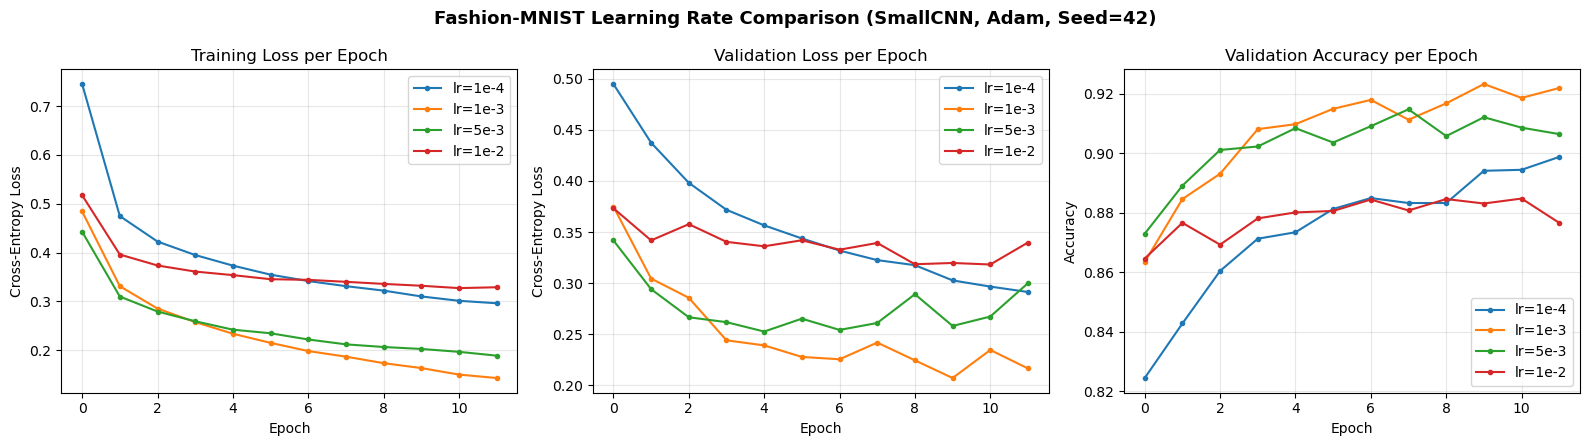

In [7]:
lr_results = {
    "lr=1e-4": (hist_1e4, sec_1e4),
    "lr=1e-3": (hist_1e3, sec_1e3),
    "lr=5e-3": (hist_5e3, sec_5e3),
    "lr=1e-2": (hist_1e2, sec_1e2),
}


def summarize(results: dict) -> pd.DataFrame:
    rows = []
    for name, (hist, sec) in results.items():
        best_idx = hist["val_acc"].idxmax()
        rows.append({
            "run": name,
            "best_epoch": int(hist.loc[best_idx, "epoch"]),
            "best_val_acc": round(float(hist.loc[best_idx, "val_acc"]), 4),
            "final_val_loss": round(float(hist["val_loss"].iloc[-1]), 4),
            "epochs_ran": len(hist),
            "seconds": round(sec, 1),
        })
    return pd.DataFrame(rows).sort_values("best_val_acc", ascending=False).reset_index(drop=True)


def plot_runs(results: dict, title: str):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for name, (hist, _) in results.items():
        axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", markersize=3, label=name)
        axes[1].plot(hist["epoch"], hist["val_loss"], marker="o", markersize=3, label=name)
        axes[2].plot(hist["epoch"], hist["val_acc"], marker="o", markersize=3, label=name)

    axes[0].set_title("Training Loss per Epoch")
    axes[1].set_title("Validation Loss per Epoch")
    axes[2].set_title("Validation Accuracy per Epoch")
    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.grid(True, alpha=0.3)
        ax.legend()

    axes[0].set_ylabel("Cross-Entropy Loss")
    axes[1].set_ylabel("Cross-Entropy Loss")
    axes[2].set_ylabel("Accuracy")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig("lr_comparison_curves.png", dpi=150, bbox_inches="tight")
    plt.show()


summary_df = summarize(lr_results)
display(summary_df)
plot_runs(lr_results, title="Fashion-MNIST Learning Rate Comparison (SmallCNN, Adam, Seed=42)")

## 5. Discussion: Why Did This Happen?

Putting all four runs side by side confirms what optimization theory predicts about step sizes on a curved loss surface:

* **Why `lr = 1e-3` won (92.33% peak accuracy, 0.2164 final val loss):** Adam’s default step size hits the "Goldilocks zone." It is large enough to traverse flat regions early on, yet small enough for Adam's adaptive momentum and per-parameter scaling to settle cleanly into a narrow, generalizable minimum by Epoch 9 without bouncing out.
* **Why both extremes failed for opposite reasons:** 
  * `lr = 1e-4` (89.88% peak accuracy) never suffered an unstable epoch, but its tiny updates left the model underfitted when the 12-epoch clock ran out—its validation loss (`0.2912`) was still steadily dropping at Epoch 11.
  * `lr = 1e-2` (88.48% peak accuracy, 0.3397 final val loss) took steps so large that the weights repeatedly overshot the narrow valleys where fine clothing textures live, creating wild validation spikes despite running for the exact same ~314 seconds on CPU.
* **Why final validation loss tells a deeper story than peak accuracy:** Looking only at `best_val_acc` makes `lr = 5e-3` (91.48%) look like a close runner-up. However, its jagged validation curve and high `final_val_loss` (`0.2999`—worse than ultra-slow `1e-4`) show that it kept oscillating around the bottom of the valley rather than converging smoothly.
* **Zero extra compute cost:** Every run took between `307.3s` and `314.2s` because all four executed the exact same number of forward and backward passes (12 epochs × 844 batches). Tuning the learning rate yielded a +3.85% accuracy gain over `1e-2` for zero additional compute.

### Limitations & Reproducibility
1. **Model and dataset specificity:** These exact numbers apply to a 206K-parameter `SmallCNN` on 28×28 grayscale Fashion-MNIST images. Moving to deeper architectures (like ResNet), adding Batch Normalization, switching to full-color datasets (CIFAR-10), or swapping Adam for SGD shifts the loss landscape and requires re-tuning.
2. **Fixed 12-epoch budget and single seed:** All runs were capped at 12 epochs from a single seed (`seed=42`). Given 35–40 epochs, `lr = 1e-4` would likely catch up, and pairing `lr = 5e-3` with a learning rate scheduler would let it sprint early and settle smoothly at the end.
3. **Full reproducibility:** Because every run initializes `L.seed_everything(42, workers=True)`, PyTorch locks weight initialization and data shuffling. Anyone can clone the notebook from [my GitHub repository](https://github.com/Vancey041/ds-portfolio) and click **Run All** to reproduce these exact curves.

## 6. Practical Takeaways & References

### Key Takeaways for Training Your Own Models
1. **Sweep powers of 10 first:** When starting with a new dataset or architecture, test 3–4 learning rates spaced by orders of magnitude (`1e-4`, `1e-3`, `1e-2`) for a short epoch budget before touching deeper hyperparameters.
2. **Judge stability with validation loss, not just peak accuracy:** A lucky spike in validation accuracy can hide unstable training. Always inspect the validation loss curve—pick the largest learning rate whose loss trends downward smoothly without sharp zig-zags.
3. **Combine larger learning rates with schedulers if you need speed:** If `1e-3` feels too slow on a larger project, start near `5e-3` and attach a learning rate scheduler (like Cosine Annealing or `ReduceLROnPlateau`) to shrink the step size as training progresses.

### References
* **Adam Optimizer:** Kingma, D. P., & Ba, J. (2014). *Adam: A Method for Stochastic Optimization*. [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)
* **Dataset:** Xiao, H., Rasul, K., & Vollgraf, R. (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*. [arXiv:1708.07747](https://arxiv.org/abs/1708.07747)
* **Framework:** Falcon, W., & The PyTorch Lightning Team. *PyTorch Lightning Documentation — Reproducibility & Trainer API*. [lightning.ai/docs/pytorch](https://lightning.ai/docs/pytorch/stable/)
* **Experiment Code & Artifacts:** Edio, V. R. T. (2026). *Data Science Portfolio — Learning Rate Hyperparameter Study*. [github.com/Vancey041/ds-portfolio](https://github.com/Vancey041/ds-portfolio)